In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### Загрузим уже обработанные в прошлом ДЗ данные!

In [3]:
df = pd.read_csv('processed_sigma.csv')
df = df.drop("Trip_ID", axis=1)

X = df.drop("Surge_Pricing_Type", axis=1)
y = df["Surge_Pricing_Type"]

### Principal component analysis (PCA)

**Задание 1.** Спроецируйте данные на двумерную плоскость, используя `PCA`. Другими словами, выделите первые две главные компоненты и изобразите данные в осях этих компонент. Не забудьте центрировать признаки перед применением метода. 

**Какую долю изначальной дисперсии (информации) содержат/объясняют в себе обе компоненты?** Для этого воспользуйтесь атрибутом `explained_variance_ratio_` у PCA-класса.

In [4]:
### Центрируем данные

### Your code is here

X_centered = X - X.mean()
X_centered.sum()

Trip_Distance                    3.074092e-10
Customer_Since_Months           -8.355983e-12
Life_Style_Index                -1.373479e-11
Customer_Rating                  1.469402e-11
Cancellation_Last_1Month         1.251976e-11
Var1                             1.982698e-10
Var2                            -3.263949e-10
Var3                             6.161827e-10
Type_of_Cab_B                    3.694822e-13
Type_of_Cab_C                    5.115908e-13
Type_of_Cab_D                   -1.193712e-12
Type_of_Cab_E                    5.044853e-13
Confidence_Life_Style_Index_B   -3.971934e-12
Confidence_Life_Style_Index_C   -8.597567e-13
Destination_Type_B              -1.016076e-12
Destination_Type_C              -2.913225e-12
Destination_Type_D              -1.705303e-13
Destination_Type_E               1.257661e-12
Destination_Type_F               3.304024e-13
Destination_Type_G              -6.465939e-13
Destination_Type_H              -5.151435e-14
Destination_Type_I              -1

In [5]:
from sklearn.decomposition import PCA

### Your code is here
pca = PCA(n_components=2)

pca.fit(X_centered)

,n_components,2
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [6]:
print(pca.explained_variance_ratio_.round(3))

[0.632 0.211]


**Задание 2.** Изобразите heatmap корреляции изначальных признаков с новыми двумя главными компонентами. \
**Какие признаки коррелируют с первой компонентой? Какие со второй? В качестве порогового значения договоримся о корреляции >= 0.5 по абсолютному значению **


In [7]:
### Your code is here

PCA_dataset = pca.fit_transform(X_centered)

PCA_dataset = pd.DataFrame(PCA_dataset, columns=['PCA_1', 'PCA_2'])

In [8]:
PCA_dataset

,PCA_1,PCA_2
0,-38.743132,-23.282634
1,-13.209252,-25.023815
2,-2.004910,-1.637085
3,17.178458,-0.907657
4,14.477389,-11.656752
...,...,...
131657,-32.267779,-2.482906
131658,32.621206,-0.886322
131659,-4.045367,-1.565545
131660,3.696395,-15.487904


In [9]:
first_conponent_corr = X_centered.corrwith(PCA_dataset.PCA_1)
second_conponent_corr = X_centered.corrwith(PCA_dataset.PCA_2)

corrs = pd.concat([first_conponent_corr, second_conponent_corr], axis=1)
corrs.columns = ['PCA_1', 'PCA_2']
corrs

,PCA_1,PCA_2
Trip_Distance,0.997767,0.018410
Customer_Since_Months,0.121591,0.003500
Life_Style_Index,0.480658,-0.025901
Customer_Rating,-0.070104,-0.003757
Cancellation_Last_1Month,0.000803,0.008960
Var1,-0.048532,0.998600
Var2,0.247178,-0.028448
Var3,0.293819,-0.026583
Type_of_Cab_B,-0.048751,0.005723
Type_of_Cab_C,-0.012059,-0.003397


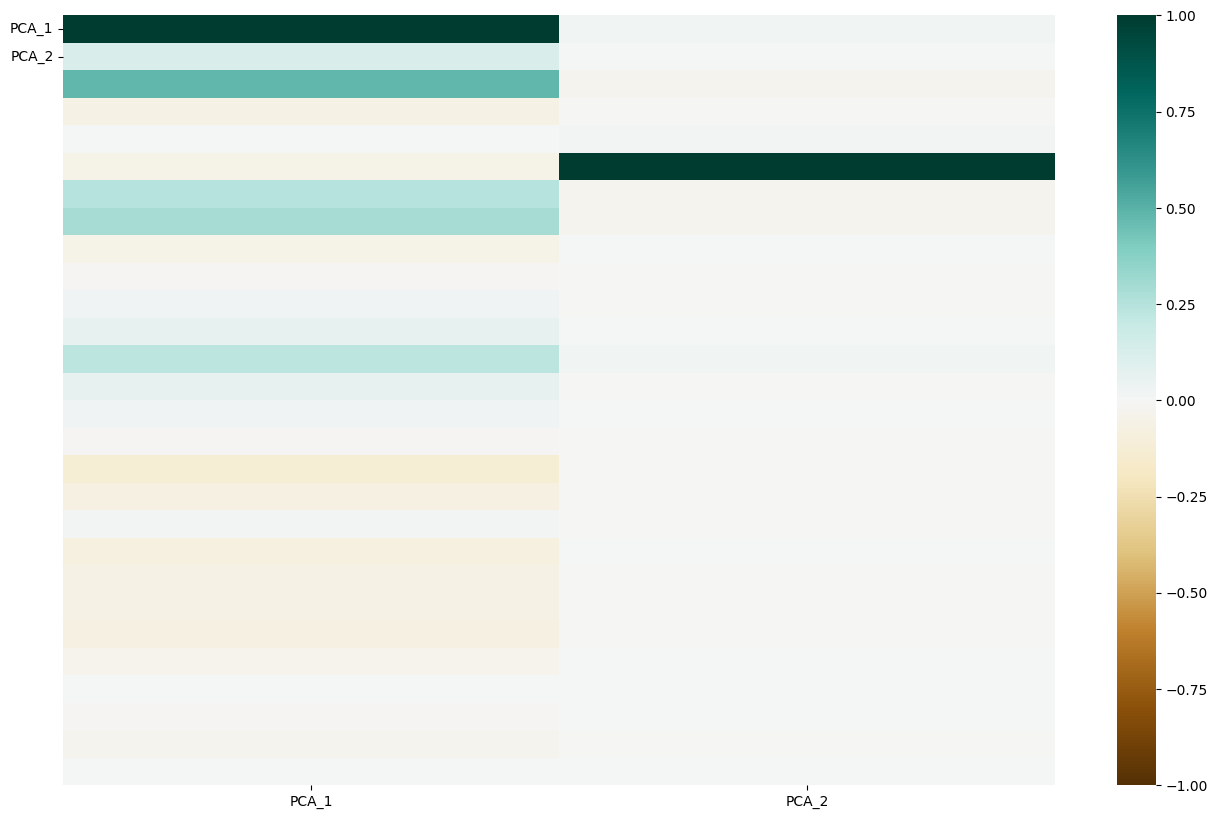

In [10]:
import seaborn as sns

fig = plt.figure()

fig.set_size_inches(16, 10)

sns.heatmap(corrs,
            xticklabels=corrs.columns,
            yticklabels=corrs.columns,
            cmap='BrBG',
            vmin=-1,
            vmax=1
            )

plt.show()

**Задание 3.** Изобразите двумерную проекцию данных с метками классов. Выделите третью главную компоненту и аналогично нарисуйте трехмерную проекцию с метками классов. \
**Какие признаки коррелируют с третьей компонентой?**

In [11]:
### Your code is here

PCA_dataset = np.concatenate((PCA_dataset.values, y.values.reshape(-1, 1)), axis=1)
PCA_dataset = pd.DataFrame(PCA_dataset, columns=['PCA_1', 'PCA_2', 'Surge_Pricing_Type'])
PCA_dataset

,PCA_1,PCA_2,Surge_Pricing_Type
0,-38.743132,-23.282634,2.0
1,-13.209252,-25.023815,2.0
2,-2.004910,-1.637085,2.0
3,17.178458,-0.907657,3.0
4,14.477389,-11.656752,2.0
...,...,...,...
131657,-32.267779,-2.482906,3.0
131658,32.621206,-0.886322,2.0
131659,-4.045367,-1.565545,2.0
131660,3.696395,-15.487904,2.0


<Axes: xlabel='PCA_1', ylabel='PCA_2'>

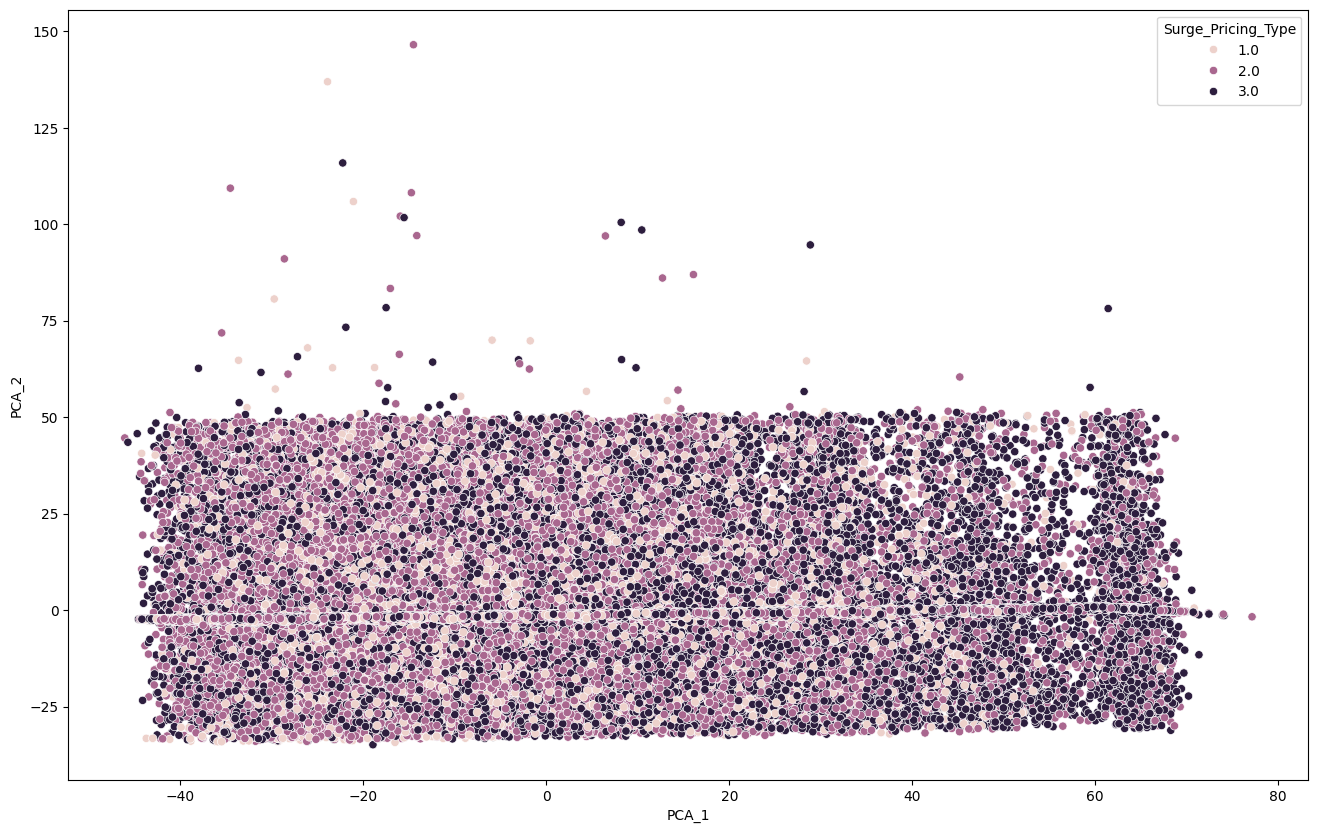

In [12]:
fig = plt.figure()

fig.set_size_inches(16, 10)

sns.scatterplot(data=PCA_dataset, x='PCA_1', y='PCA_2', hue='Surge_Pricing_Type')

# plt.show()

Советуем еще и замерить попарные корреляции между главными компонентами! Это поможет в ответе на один из тестовых вопросов.

In [13]:
### Your code is here
pca3 = PCA(n_components=3)

PCA_dataset3 = pca3.fit_transform(X_centered)

PCA_dataset3 = pd.DataFrame(PCA_dataset3, columns=['PCA_1', 'PCA_2', 'PCA_3'])

first_conponent_corr3 = X_centered.corrwith(PCA_dataset3.PCA_1)
second_conponent_corr3 = X_centered.corrwith(PCA_dataset3.PCA_2)
third_conponent_corr3 = X_centered.corrwith(PCA_dataset3.PCA_3)

corrs3 = pd.concat([first_conponent_corr3, second_conponent_corr3,third_conponent_corr3], axis=1)
corrs3.columns = ['PCA_1', 'PCA_2', 'PCA_3']
corrs3


,PCA_1,PCA_2,PCA_3
Trip_Distance,0.997767,0.018410,-0.064176
Customer_Since_Months,0.121591,0.003500,0.081370
Life_Style_Index,0.480658,-0.025901,0.166688
Customer_Rating,-0.070104,-0.003757,-0.236793
Cancellation_Last_1Month,0.000803,0.008960,0.136222
Var1,-0.048532,0.998600,0.021003
Var2,0.247178,-0.028448,0.705159
Var3,0.293819,-0.026583,0.951081
Type_of_Cab_B,-0.048751,0.005723,0.011211
Type_of_Cab_C,-0.012059,-0.003397,-0.008707


In [15]:
print(PCA_dataset3.corr().round(3))

       PCA_1  PCA_2  PCA_3
PCA_1    1.0   -0.0   -0.0
PCA_2   -0.0    1.0    0.0
PCA_3   -0.0    0.0    1.0


In [16]:
PCA_dataset3

,PCA_1,PCA_2,PCA_3
0,-38.743132,-23.282634,-11.303274
1,-13.209252,-25.023815,5.664106
2,-2.004910,-1.637085,3.663032
3,17.178458,-0.907657,-3.191676
4,14.477389,-11.656752,22.999348
...,...,...,...
131657,-32.267779,-2.482906,3.955203
131658,32.621206,-0.886322,11.438623
131659,-4.045367,-1.565545,-0.451941
131660,3.696395,-15.487904,3.655981


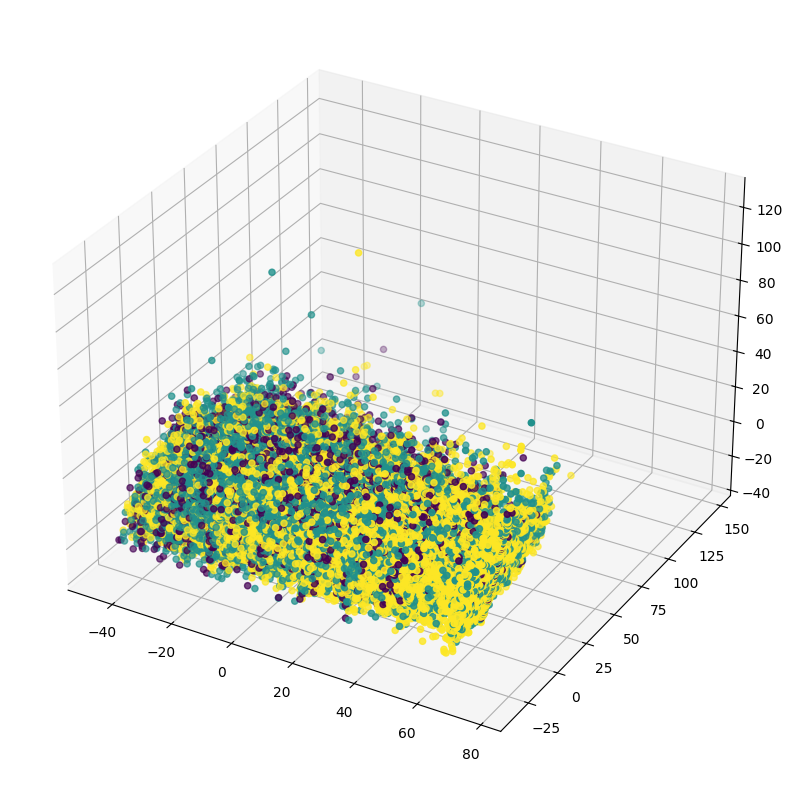

In [17]:
PCA_dataset3 = np.concatenate((PCA_dataset3.values, y.values.reshape(-1, 1)), axis=1)
PCA_dataset3 = pd.DataFrame(PCA_dataset3, columns=['PCA_1', 'PCA_2', 'PCA_3','Surge_Pricing_Type'])


fig = plt.figure()

fig.set_size_inches(16, 10)
ax = plt.axes(projection='3d')

colors = PCA_dataset3['Surge_Pricing_Type'].replace(['A','B','C', 'D'],['orange', 'blue', 'green', 'red'])
ax.scatter3D(PCA_dataset3['PCA_1'], PCA_dataset3['PCA_2'], PCA_dataset3['PCA_3'], c=colors)

**Задание 4.** Обучите логистическую регрессию на первых двух компонентах центрированных данных и подберите гиперпараметры. Обучите логистическую регрессию на центрированных данных и подберите гиперпараметры. **Сравните метрику accuracy и f1-score на тестовой выборке в двух моделях**.

P.S. для удобства, скорости и нормализации данных (понадобится, так как захотим повалидироваться на параметрах регуляризации) можно построить конструкцию Pipeline c 3 следующими степами: StandardScaler -> PCA -> LogisticRegression

In [18]:
np.random.seed(2022)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X_centered, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)

In [ ]:
### Your code is here

pipe_pca_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('model', LogisticRegression(solver='saga'))
])

# param_grid_2d = {
#     'pca__n_components':[2], 
#     'model__penalty': ['l1', 'l2', 'elasticnet'],
#     'model__C': [1e-5, 0.0001, 0.001, 0.01]}


param_grid_2d = [
    # Группа 1: Обычные L1 и L2 регуляризации (l1_ratio здесь НЕ нужен)
    {
        'pca__n_components':[2],
        'model__solver': ['saga'],  # saga поддерживает и l1, и l2
        'model__penalty': ['l1', 'l2'],
        'model__C': [1e-5, 0.0001, 0.001, 0.01]
    },
    
    # Группа 2: Настройки специально для ElasticNet
    {
        'pca__n_components':[2],
        'model__solver': ['saga'],  # только saga поддерживает elasticnet
        'model__penalty': ['elasticnet'],
        'model__C': [1e-5, 0.0001, 0.001, 0.01],
        'model__l1_ratio': [0.2, 0.5, 0.8]  # <--- ДОБАВЛЯЕМ СЮДА ПЕРЕБОР l1_ratio
    }
]


grid_search_pca_2d = GridSearchCV(
    pipe_pca_lr,
    param_grid_2d,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    error_score='raise'
)

# 4. Обучаем модель (передаем исходные базовые X_train и y_train)
grid_search_pca_2d.fit(X_train, y_train)

# 5. Делаем предсказание на тестовой выборке и оцениваем результат
y_pred_pca = grid_search_pca_2d.predict(X_test)

print(f"Лучшие параметры: {grid_search_pca_2d.best_params_}\n")
print(classification_report(y_test, y_pred_pca, digits=3))




Лучшие параметры: {'model__C': 0.0001, 'model__l1_ratio': 0.2, 'model__penalty': 'elasticnet', 'model__solver': 'saga', 'pca__n_components': 2}

              precision    recall  f1-score   support

           1      0.000     0.000     0.000      5372
           2      0.481     0.724     0.578     11349
           3      0.512     0.493     0.502      9612

    accuracy                          0.492     26333
   macro avg      0.331     0.406     0.360     26333
weighted avg      0.394     0.492     0.433     26333



In [24]:
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='saga'))
])


param_grid = [
    # Группа 1: Обычные L1 и L2 регуляризации (l1_ratio здесь НЕ нужен)
    {
        'model__solver': ['saga'],  # saga поддерживает и l1, и l2
        'model__penalty': ['l1', 'l2'],
        'model__C': [1e-5, 0.0001, 0.001, 0.01]
    },
    
    # Группа 2: Настройки специально для ElasticNet
    {
        'model__solver': ['saga'],  # только saga поддерживает elasticnet
        'model__penalty': ['elasticnet'],
        'model__C': [1e-5, 0.0001, 0.001, 0.01],
        'model__l1_ratio': [0.2, 0.5, 0.8]  # <--- ДОБАВЛЯЕМ СЮДА ПЕРЕБОР l1_ratio
    }
]


grid_search_pca = GridSearchCV(
    pipe_lr,
    param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    error_score='raise'
)

# 4. Обучаем модель (передаем исходные базовые X_train и y_train)
grid_search_pca.fit(X_train, y_train)

# 5. Делаем предсказание на тестовой выборке и оцениваем результат
y_pred_pca = grid_search_pca.predict(X_test)

print(f"Лучшие параметры: {grid_search_pca.best_params_}\n")
print(classification_report(y_test, y_pred_pca, digits=3))

Лучшие параметры: {'model__C': 0.001, 'model__penalty': 'l2', 'model__solver': 'saga'}

              precision    recall  f1-score   support

           1      0.746     0.532     0.621      5372
           2      0.636     0.830     0.720     11349
           3      0.736     0.589     0.655      9612

    accuracy                          0.681     26333
   macro avg      0.706     0.650     0.665     26333
weighted avg      0.695     0.681     0.676     26333



Кажется, достаточно сильно теряем в качестве! Может, добавить компонент?

**Задание 5.** Обучите модели логистической регресии на нескольких различных компонентах: [2, 4, 8, 16, 28]. **Нарисуйте графики зависимости accuracy, f1-score от количества компонент. Введите их значения через запятую**. При обучении используйте l2-регуляризацию, гиперпараметр C подбирайте по сетке. 


In [25]:
### Чтобы не заставлять вас писать похожий на предыдущий код,
### Написали функцию, которая будет обучать модель для
### произвольного числа n_components главных компонент.

def train_pca_i(n_components, X_train, y_train):
    pipe = Pipeline([('scaler', StandardScaler()), 
                     ('pca', PCA(n_components=n_components)),
                     ('model', LogisticRegression(penalty='l2', solver='saga',random_state=1))])
    
    param_grid = {'model__C': [0.0001, 0.001, 0.01, 0.1]}
    
    grid = GridSearchCV(pipe, param_grid, cv=5)
    grid.fit(X_train, y_train)
    
    report = classification_report(y_test, grid.predict(X_test), output_dict=True)
    return (report['accuracy'], 
            report['weighted avg']['f1-score'])

In [26]:
%%time
accuracy_dict, f1_score_dict = {}, {}
components_list = [2, 4, 8, 16, 28]

for n_components in components_list:
    accuracy_dict[n_components], f1_score_dict[n_components] = train_pca_i(n_components, X_train, y_train)

    
    
print(accuracy_dict)
print(f1_score_dict)

{2: 0.48429726958569097, 4: 0.5321839516955911, 8: 0.5885770705958303, 16: 0.5922606615273611, 28: 0.6813883720047089}
{2: 0.4269265169630114, 4: 0.4724230539303479, 8: 0.5231713579311364, 16: 0.5273629016033227, 28: 0.6760757307801638}
CPU times: total: 1min 52s
Wall time: 1min 53s


TypeError: type dict doesn't define __round__ method

Обычно, когда решается какая-то высокоразмерная предсказательная задача, где тысячи признаков, функция качества PCA моделей похожа на параболу ветвями вниз в зависимости от количества компонент (для совсем маленьких и больших n_component качество маленькое, при этом есть где-то промежуточное значение).

Как думаете, почему здесь у нас непрерывно растущие графики качества?

Может, изначальные признаки были слишком хороши?

### t-SNE

Напомним, что метод заключается в введении некоторых функций, основанных на расстоянии между признаками, которые измеряют близость объектов. Функций, как вы помните, две, и они заданы в исходном и новом пространствах соотвественно. Далее минимизируем дивергенцию Кульбака-Лейблера по координатaм в новом пространстве

**Задание 6.** Обучите t-sne c `n_components=2` на изначальных данных и визуализируйте результаты с учетом известных классов. 

P.S. если устанете ждать обучения TSNE, или упадет ошибка по типу oom, то можно сократить число объектов в датасете до, например, пары тысяч. Это и следующее задания никак проверяться системой не будут. Вам достаточно повторить упражнение с практики и получить какое-то более адекватное (по сравнению с PCA) изображение классов.

In [35]:
from sklearn.manifold import TSNE

### Your code is here
# X_tsne = TSNE(n_components=2 ).fit_transform(X.head(2000))

X_scaled = StandardScaler().fit_transform(X.head(2000))
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(X_scaled)

<Axes: xlabel='tsne_1', ylabel='tsne_2'>

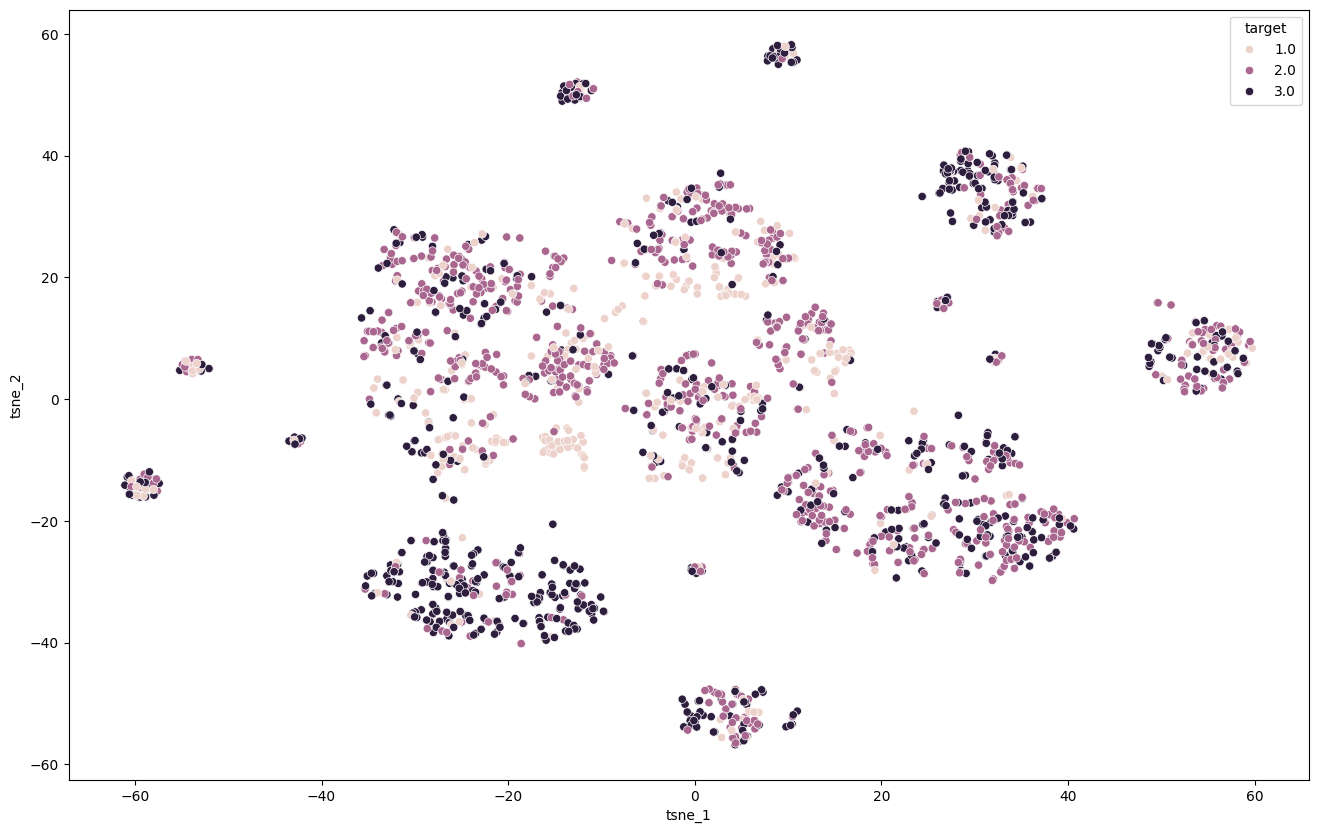

In [36]:
X_tsne  = np.concatenate([X_tsne, y.head(2000).values.reshape(-1, 1)], axis=1)

X_tsne = pd.DataFrame(X_tsne, columns=['tsne_1', 'tsne_2', 'target'])

fig = plt.figure()

fig.set_size_inches(16, 10)

sns.scatterplot(data=X_tsne, x='tsne_1', y='tsne_2', hue='target')

**Задание 7.** Обучите t-sne с `n_components=3` на изначальных данных и визуализируйте результаты с учетом известных классов.

In [37]:
### Your code is here
from sklearn.manifold import TSNE

### Your code is here
# X_tsne3 = TSNE(n_components=3).fit_transform(X.head(2000))

X_tsne3 = TSNE(n_components=3, random_state=42).fit_transform(X_scaled)


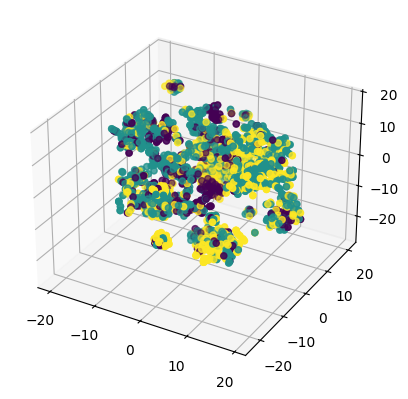

In [38]:
X_tsne3  = np.concatenate([X_tsne3, y.head(2000).values.reshape(-1, 1)], axis=1)

X_tsne3 = pd.DataFrame(X_tsne3, columns=['tsne_1', 'tsne_2', 'tsne_3', 'target'])

ax = plt.axes(projection='3d')

ax.scatter(X_tsne3['tsne_1'], X_tsne3['tsne_2'], X_tsne3['tsne_3'], c=X_tsne3['target'])

colors = X_tsne3['target'].replace(['1','2','3'],['blue', 'green', 'red'])
ax.scatter3D(X_tsne3['tsne_1'], X_tsne3['tsne_2'], X_tsne3['tsne_3'], c=colors)

Советуем обрезать датасет до маленького числа объектов (чтобы точки и их группки были хорошо различимы) и поиграться с гиперпараметрами класса Tsne! Обычно такая "игра" может привести к куда более красивым результатам по сравнению с теми, что получены с дефолтными настройками!